In [1]:
!pip install torchinfo -q

In [2]:
import torch  
import torch.nn as nn  #
import torch.optim as optim  
import numpy as np  
import matplotlib.pyplot as plt  
import pandas as pd
from torchvision import datasets, models, transforms
from torchinfo import summary
from torch.utils.data import DataLoader,random_split  
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score

c:\Users\Victus\anaconda3\Lib\site-packages\sklearn\utils\_param_validation.py:14: UserWarning: A NumPy version >=1.23.5 and <2.5.0 is required for this version of SciPy (detected version 2.5.2)
  from scipy.sparse import csr_matrix, issparse


In [3]:

print(torch.cuda.is_available())


if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))

True
NVIDIA GeForce RTX 5050 Laptop GPU


In [4]:
SEED = 42
np.random.seed(SEED)

In [5]:
base_path = r'C:\Users\Victus\Downloads\tlbioandnon\NEW_dataset\NEW_dataset'

train_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])


test_transforms = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])
train_dataset = datasets.ImageFolder(r'C:\Users\Victus\Downloads\Dataset\train', transform=train_transforms)
val_dataset=datasets.ImageFolder(r"C:\Users\Victus\Downloads\Dataset\val",transform=test_transforms)
test_dataset=datasets.ImageFolder(r'C:\Users\Victus\Downloads\Dataset\test', transform=test_transforms)


In [6]:
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=4, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, num_workers=4, pin_memory=True, persistent_workers=True)
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [7]:

model = models.efficientnet_b0(
    weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1
)


In [8]:
for param in model.parameters():
    param.requires_grad = False

In [9]:
in_features = model.classifier[1].in_features

model.classifier = nn.Sequential(
    nn.Dropout(p=0.3),
    nn.Linear(in_features, 256),
    nn.LeakyReLU(),
    nn.Dropout(p=0.5),
    nn.Linear(256, 2)
)

model = model.to(device)

In [10]:
epochs=20
learning_rate=0.01

In [11]:
criterion=nn.CrossEntropyLoss()
optimizer=optim.Adam(model.parameters(),lr=learning_rate,weight_decay=1e-4)

In [12]:
patience = 5
best_val_loss = float('inf')
epochs_no_improve=0

In [13]:
# --- EARLY STOPPING SETUP ---
patience = 5  # Number of epochs to wait before stopping if val_loss doesn't improve
best_val_loss = float('inf') # Initialize with infinity
epochs_no_improve = 0 # Counter

for epoch in range(epochs):

    # --- TRAINING PHASE ---
    model.train() # Set model to training mode
    total_train_loss = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        # Forward pass
        outputs = model(images)
        loss = criterion(outputs, labels)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()

    avg_train_loss = total_train_loss / len(train_loader)

    # --- VALIDATION PHASE ---
    model.eval() # Set model to evaluation mode (important for Dropout/BatchNorm)
    total_val_loss = 0
    
    # Disable gradient calculation for validation to save memory and speed up
    with torch.no_grad():
        for val_images, val_labels in val_loader:
            val_images, val_labels = val_images.to(device), val_labels.to(device)
            
            val_outputs = model(val_images)
            val_loss = criterion(val_outputs, val_labels)
            total_val_loss += val_loss.item()
            
    avg_val_loss = total_val_loss / len(val_loader)
    
    print(f"Epoch [{epoch+1}/{epochs}] | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f}")

    # --- EARLY STOPPING LOGIC ---
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        epochs_no_improve = 0
        # Optional but recommended: Save the model when validation loss improves
        torch.save(model.state_dict(), 'best_tlbiononbioeb_model.pth') 
        print("  => Validation loss improved. Saving model.")
    else:
        epochs_no_improve += 1
        print(f"  => No improvement in val_loss. Counter: {epochs_no_improve}/{patience}")
        
        if epochs_no_improve >= patience:
            print(f"Early stopping triggered! Training stopped at epoch {epoch+1}.")
            break # Exit the training loop

Epoch [1/20] | Train Loss: 0.2867 | Val Loss: 0.1128
  => Validation loss improved. Saving model.
Epoch [2/20] | Train Loss: 0.2111 | Val Loss: 0.2579
  => No improvement in val_loss. Counter: 1/5
Epoch [3/20] | Train Loss: 0.1792 | Val Loss: 0.1001
  => Validation loss improved. Saving model.
Epoch [4/20] | Train Loss: 0.1673 | Val Loss: 0.0826
  => Validation loss improved. Saving model.
Epoch [5/20] | Train Loss: 0.1642 | Val Loss: 0.0960
  => No improvement in val_loss. Counter: 1/5
Epoch [6/20] | Train Loss: 0.1714 | Val Loss: 0.0661
  => Validation loss improved. Saving model.
Epoch [7/20] | Train Loss: 0.1571 | Val Loss: 0.0558
  => Validation loss improved. Saving model.
Epoch [8/20] | Train Loss: 0.1597 | Val Loss: 0.0532
  => Validation loss improved. Saving model.
Epoch [9/20] | Train Loss: 0.1653 | Val Loss: 0.0926
  => No improvement in val_loss. Counter: 1/5
Epoch [10/20] | Train Loss: 0.1765 | Val Loss: 0.0971
  => No improvement in val_loss. Counter: 2/5
Epoch [11/20] |

In [14]:
model.load_state_dict(torch.load('best_tlbiononbioeb_model.pth'))
model.eval()
total = 0
correct = 0

with torch.no_grad():
    for images, labels in test_loader:
     
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total = total + labels.shape[0]
        correct = correct + (predicted == labels).sum().item()

print(f"Accuracy: {correct/total}")

Accuracy: 0.9827160493827161


In [15]:
model.load_state_dict(torch.load('best_tlbiononbioeb_model.pth'))
model.eval()
total = 0
correct = 0

with torch.no_grad():
    for images, labels in val_loader:
     
        images, labels = images.to(device), labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total = total + labels.shape[0]
        correct = correct + (predicted == labels).sum().item()

print(f"Accuracy: {correct/total}")

Accuracy: 0.9777503090234858


In [16]:
model.load_state_dict(torch.load('best_tlbiononbioeb_model.pth'))
model.eval()

total = 0
correct = 0

with torch.no_grad():

  for images, labels in train_loader:

    # move data to gpu
    images,labels = images.to(device), labels.to(device)

    outputs = model(images)

    _, predicted = torch.max(outputs, 1)

    total = total + labels.shape[0]

    correct = correct + (predicted == labels).sum().item()

print(correct/total)

0.9777015437392796


In [17]:
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score
)

import matplotlib.pyplot as plt

In [18]:

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)

        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(
            predictions.cpu().numpy()
        )

In [19]:
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=[0, 1],
        target_names=[
            "Biodegradable",
            "Non-Biodegradable"
        ],
        digits=4
    )
)

                   precision    recall  f1-score   support

    Biodegradable     0.9950    0.9706    0.9826       204
Non-Biodegradable     0.9709    0.9950    0.9828       201

         accuracy                         0.9827       405
        macro avg     0.9829    0.9828    0.9827       405
     weighted avg     0.9830    0.9827    0.9827       405



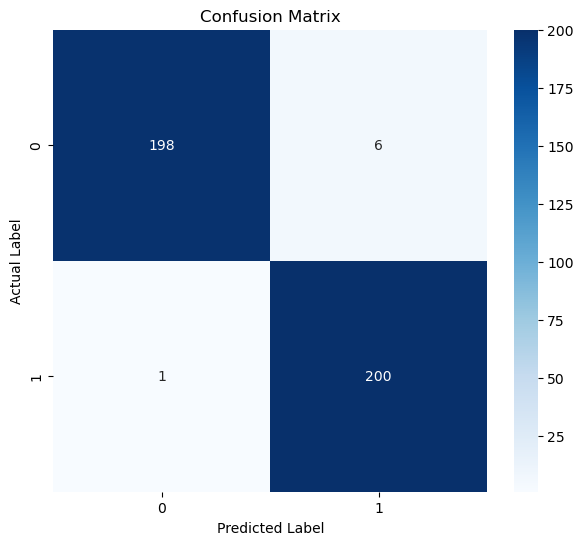

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0,1]
)

plt.figure(figsize=(7,6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.show()

In [21]:
import torch
from PIL import Image

# 1. Detect your graphics card
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class_names = {0: "Biodegradable", 1: "Non-Biodegradable"}

# Load the model
model.load_state_dict(torch.load('best_tlbiononbioeb_model.pth'))
# 2. Move the model to the graphics card
model.to(device) 
model.eval()

def predict(image_path):
    image = Image.open(image_path).convert("RGB")
    input_tensor = test_transforms(image).unsqueeze(0)  # add batch dimension
    
    # 3. Move the image to the graphics card so it matches the model
    input_tensor = input_tensor.to(device) 

    with torch.no_grad():
        outputs = model(input_tensor)
        probabilities = torch.softmax(outputs, dim=1)
        confidence, predicted_class = torch.max(probabilities, dim=1)

    label = class_names[predicted_class.item()]
    print(f"Prediction: {label}  (confidence: {confidence.item()*100:.2f}%)")
    return label


In [22]:

predict(r"C:\Users\Victus\Downloads\plastic707_jpg.rf.d6685ce737a254a3ea8c77c80d543001.jpg")

Prediction: Non-Biodegradable  (confidence: 91.81%)


'Non-Biodegradable'

In [23]:
predict(r"C:\Users\Victus\Downloads\biodegradable144_jpg.rf.b9ff07ce047a0cba394b105147ffe7de.jpg")

Prediction: Biodegradable  (confidence: 95.60%)


'Biodegradable'